## Inicialización

In [10]:
import warnings

import sys
import os
# Le dice python que busque liberrías ahí también
sys.path.append(os.path.join('../src'))
import funciones_personales as fp

import math
import re
import time

import numpy as np
import pandas as pd

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from tqdm.auto import tqdm

import sklearn.metrics as metrics

from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

In [13]:
%matplotlib inline
%config InlineBackend.figure_format = 'png'
# la siguiente línea proporciona gráficos de mejor calidad en pantallas HiDPI
# %config InlineBackend.figure_format = 'retina'

In [11]:
# esto es para usar progress_apply, puedes leer más en https://pypi.org/project/tqdm/#pandas-integration
tqdm.pandas()

## Cargar datos

In [17]:
df_reviews = pd.read_csv('../data/imdb_reviews.tsv', sep='\t', dtype={'votes': 'Int64'})

In [18]:
print('Dimensiones del dataset:')
print(df_reviews.shape)

print('\nInformación general:')
df_reviews.info()

display(df_reviews.head())

Dimensiones del dataset:
(47331, 17)

Información general:


<class 'pandas.DataFrame'>
RangeIndex: 47331 entries, 0 to 47330
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   tconst           47331 non-null  str    
 1   title_type       47331 non-null  str    
 2   primary_title    47331 non-null  str    
 3   original_title   47331 non-null  str    
 4   start_year       47331 non-null  int64  
 5   end_year         47331 non-null  str    
 6   runtime_minutes  47331 non-null  str    
 7   is_adult         47331 non-null  int64  
 8   genres           47331 non-null  str    
 9   average_rating   47329 non-null  float64
 10  votes            47329 non-null  Int64  
 11  review           47331 non-null  str    
 12  rating           47331 non-null  int64  
 13  sp               47331 non-null  str    
 14  pos              47331 non-null  int64  
 15  ds_part          47331 non-null  str    
 16  idx              47331 non-null  int64  
dtypes: Int64(1), float64(1)

,tconst,title_type,primary_title,original_title,start_year,end_year,runtime_minutes,is_adult,genres,average_rating,votes,review,rating,sp,pos,ds_part,idx
0,tt0068152,movie,$,$,1971,\N,121,0,"Comedy,Crime,Drama",6.3,2218,The pakage implies that Warren Beatty and Gold...,1,neg,0,train,8335
1,tt0068152,movie,$,$,1971,\N,121,0,"Comedy,Crime,Drama",6.3,2218,How the hell did they get this made?! Presenti...,1,neg,0,train,8336
2,tt0313150,short,'15','15',2002,\N,25,0,"Comedy,Drama,Short",6.3,184,There is no real story the film seems more lik...,3,neg,0,test,2489
3,tt0313150,short,'15','15',2002,\N,25,0,"Comedy,Drama,Short",6.3,184,Um .... a serious film about troubled teens in...,7,pos,1,test,9280
4,tt0313150,short,'15','15',2002,\N,25,0,"Comedy,Drama,Short",6.3,184,I'm totally agree with GarryJohal from Singapo...,9,pos,1,test,9281


In [ ]:
missing_values = (
    df_reviews
    .isna()
    .sum()
    .sort_values(ascending=False)
)

display(missing_values[missing_values > 0])

average_rating    2
votes             2
dtype: int64

### Conclusión de la primera inspección

**Hallazgos**:

* 47,331 registros
* 17 columnas
* La columna objetivo pos está completa.
* La columna review, que será nuestra principal variable predictora, también está completa.
* Solo existen 2 valores faltantes en:
    * average_rating
    * votes
    * Ninguna de esas dos columnas será necesaria para construir nuestros modelos de clasificación de texto.

**Decisiones**

* Por ahora, no necesitamos eliminar filas ni imputar esos valores faltantes.
* Ya que metodológicamente nuestros modelos utilizarán principalmente:
    * `review  →  TF-IDF  →  modelo de clasificación  →  pos`
    * Se decide on modificar el dataset aún.

## EDA

### Exploración del balanceo de clases

In [19]:
# Mustra la canidad y porcebtaje de reseñas positivas y negativas en todo el dataset
class_counts = (
    df_reviews['pos']
    .value_counts()
    .sort_index()
)

class_percentages = (
    df_reviews['pos']
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

resumen_clases = pd.DataFrame({
    'Cantidad': class_counts,
    'Porcentaje': class_percentages
})

resumen_clases.index = [
    'Negativa (0)',
    'Positiva (1)'
]

display(resumen_clases)

,Cantidad,Porcentaje
Negativa (0),23715,50.104583
Positiva (1),23616,49.895417


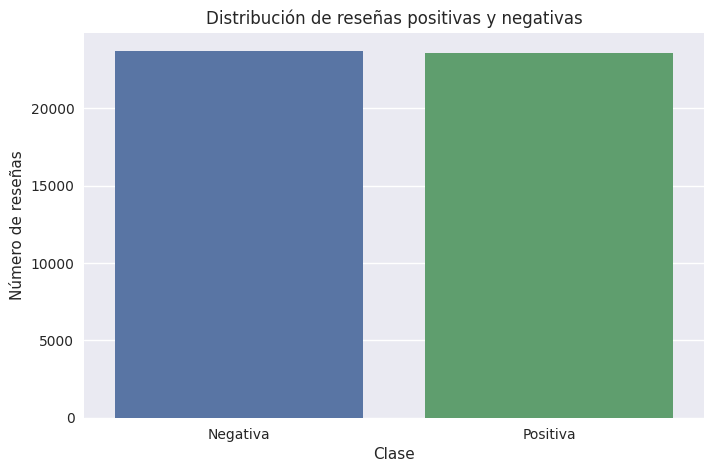

In [ ]:
# Gráfico de distribución de reseñas positivas y negativas de todo el dataset
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_reviews,
    x='pos'
)

plt.title('Distribución de reseñas positivas y negativas')
plt.xlabel('Clase')
plt.ylabel('Número de reseñas')

plt.xticks(
    ticks=[0, 1],
    labels=['Negativa', 'Positiva']
)

plt.show()

In [20]:
# Muestra la distribución de reseñas entre test y train
resumen_particiones = pd.crosstab(
    df_reviews['ds_part'],
    df_reviews['pos'],
    normalize='index'
) * 100

resumen_particiones.columns = [
    'Negativa (0)',
    'Positiva (1)'
]

display(resumen_particiones)

print(
    pd.crosstab(
        df_reviews['ds_part'],
        df_reviews['pos']
    )
)

,Negativa (0),Positiva (1)
ds_part,,
test,50.150839,49.849161
train,50.058833,49.941167


pos          0      1
ds_part              
test     11803  11732
train    11912  11884


#### Conclusión del balanceo de clases

El conjunto de datos se encuentra prácticamente balanceado tanto en el dataset completo como en las particiones de entrenamiento y prueba. La diferencia entre reseñas negativas y positivas es inferior al 1%, por lo que no se observa un problema significativo de desequilibrio de clases. En consecuencia, inicialmente no será necesario aplicar técnicas de balanceo como oversampling, undersampling o ponderación de clases.

### Exploracion de las reseñas

Se realizará un breve EDA sin explorar las 17 columnas, porque el objetivo es clasificar usando principalmente:

`review → pos`

Pero se analizarán algunas características de las reseñas como:

* Longitud de las reseñas.
* Diferencias de longitud entre positivas y negativas.
* Algunos ejemplos reales de texto.

In [21]:
# crea columnas auxiliares para analizar las reseñas
df_reviews['review_length'] = (
    df_reviews['review'].str.len()
)

df_reviews['word_count'] = (
    df_reviews['review'].str.split().str.len()
)

display(
    df_reviews[
        ['pos', 'review_length', 'word_count']
    ].describe()
)

,pos,review_length,word_count
count,47331.000000,47331.000000,47331.000000
mean,0.498954,1290.030973,229.428831
std,0.500004,974.976807,170.075447
min,0.000000,32.000000,4.000000
25%,0.000000,691.000000,125.500000
50%,0.000000,957.000000,172.000000
75%,1.000000,1566.000000,278.000000
max,1.000000,13594.000000,2459.000000


In [22]:
# Comparación de estadísticas por sentimiento 
resumen_longitud = (
    df_reviews
    .groupby('pos')[
        ['review_length', 'word_count']
    ]
    .agg(
        ['mean', 'median', 'min', 'max']
    )
)

display(resumen_longitud)

review_length                    word_count                 
             mean median min    max        mean median min   max
pos                                                             
0     1273.014421  959.0  32   8698  227.516677  173.0   4  1491
1     1307.118860  955.0  65  13594  231.349001  171.0  10  2459

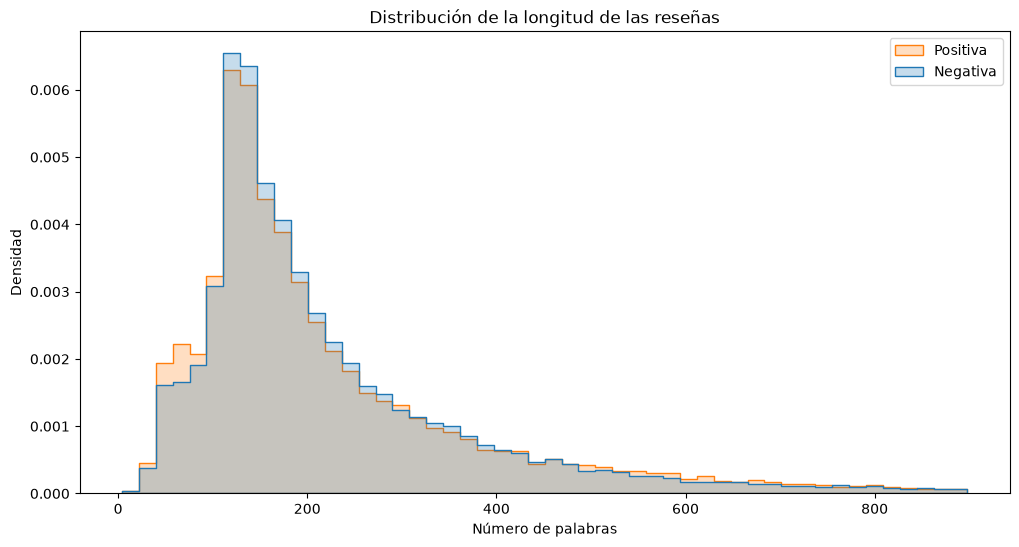

In [23]:
# Muestra la distribución de longitud de las reseñas (toma hasta el percentil 99)
limite_palabras = (
    df_reviews['word_count']
    .quantile(0.99)
)

plt.figure(figsize=(12, 6))

sns.histplot(
    data=df_reviews[
        df_reviews['word_count'] <= limite_palabras
    ],
    x='word_count',
    hue='pos',
    bins=50,
    stat='density',
    common_norm=False,
    element='step'
)

plt.title(
    'Distribución de la longitud de las reseñas'
)

plt.xlabel('Número de palabras')
plt.ylabel('Densidad')

plt.legend(
    labels=['Positiva', 'Negativa']
)

plt.show()

In [24]:
# ejemplos de reseñas con sentimiento
for sentimiento, etiqueta in [
    (0, 'RESEÑA NEGATIVA'),
    (1, 'RESEÑA POSITIVA')
]:

    print('=' * 80)
    print(etiqueta)
    print('=' * 80)

    ejemplo = (
        df_reviews[
            df_reviews['pos'] == sentimiento
        ]
        ['review']
        .sample(
            1,
            random_state=42 + sentimiento
        )
        .iloc[0]
    )

    print(ejemplo[:1500])
    print()

RESEÑA NEGATIVA
Nick Millard aka Nick Phillips should have left well-enough alone when he made "Criminally Insane" 10 years before the release of this god-awful waste of time and effort. The fact that the original "Criminally Insane" was less than an hour in length should have clued him into the fact that he had probably milked this storyline for all he was going to get out of it...but instead he opts to use TONS of footage from the original in this one as well, even to the point of recycling the original opening credit sequence! Unfortunately, bringing back the rapidly aging Priscilla Alden did not save this one. What little bit of original footage there was in this flick looks as if it were filmed with a rented hand-held camcorder! If this film cost more than $100 to make I would be very surprised and I would be equally surprised if it made anything close to that amount! Avoid this one and watch the original instead!

RESEÑA POSITIVA
There are one or two other Shemp-era shorts I like

#### Conclusión sobre la longitud de las reseñas

**Hallazgos**:

* Las reseñas cuentan con una longitud considerable:
    * Promedio: ~229 palabras.
    * Mediana: ~172 palabras.
    * El 50 % central está aproximadamente entre 126 y 278 palabras.
    * Existen algunas reseñas extremadamente largas, con un máximo de 2,459 palabras.


* Al comparar las clases

|Clase | Media palabras | Mediana palabras|
|---|---|---|
|Negativa | 227.5 | 173 |
| Positiva | 231.3 | 171 |

Las diferencias son muy pequeñas.

* Aunque existen zonas donde visualmente parece haber una ligera mayor concentración de una clase u otra, las distribuciones se superponen casi por completo.

**Conclusiones**

La longitud de las reseñas presenta una distribución similar para las clases positiva y negativa. Las reseñas positivas tienen un promedio de aproximadamente 231 palabras, mientras que las negativas tienen aproximadamente 228 palabras. Las diferencias observadas en la distribución son pequeñas y las curvas se superponen ampliamente. Por lo tanto, la longitud del texto por sí sola no parece ser una característica suficientemente discriminante para clasificar el sentimiento de las reseñas. El contenido y las palabras utilizadas en las reseñas serán más relevantes para el modelado.

La consecuensia natural de lo anterior nos lleva a TF-IDF, ya que queremos transformar el contenido textual en características numéricas.

## Procedimiento de evaluación

### Separación de datos:
```
Dataset completo
│
├── ds_part = train
│      │
│      ├── train interno → 80 %
│      │
│      └── validation → 20 %
│
└── ds_part = test
       │
       └── test final
```

In [26]:
# Separación de train y test originales
df_train = (
    df_reviews[
        df_reviews['ds_part'] == 'train'
    ]
    .copy()
)

df_test = (
    df_reviews[
        df_reviews['ds_part'] == 'test'
    ]
    .copy()
)

print('Train original:', df_train.shape)
print('Test original:', df_test.shape)

Train original: (23796, 19)
Test original: (23535, 19)


In [27]:
# Separación de texto y objetivo sin tokenización aún
X = df_train['review']
y = df_train['pos']

X_test_final = df_test['review']
y_test_final = df_test['pos']

print('X train:', X.shape)
print('y train:', y.shape)

print('\nX test final:', X_test_final.shape)
print('y test final:', y_test_final.shape)

X train: (23796,)
y train: (23796,)

X test final: (23535,)
y test final: (23535,)


In [28]:
# Split de los datos de train en train y validations
from sklearn.model_selection import train_test_split

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    # Se usa stratify para garantizar misma proporción de reseñas entre los conjuntos
    stratify=y
)

print('Entrenamiento interno:')
print(X_train.shape)

print('\nValidación:')
print(X_valid.shape)

Entrenamiento interno:
(19036,)

Validación:
(4760,)


Comprobación del balance

In [29]:
resumen_split = pd.DataFrame({
    'Train': y_train.value_counts(normalize=True) * 100,
    'Validation': y_valid.value_counts(normalize=True) * 100,
    'Test final': y_test_final.value_counts(normalize=True) * 100
})

resumen_split.index = [
    'Negativa (0)',
    'Positiva (1)'
]

display(resumen_split)

,Train,Validation,Test final
Negativa (0),50.057785,50.063025,50.150839
Positiva (1),49.942215,49.936975,49.849161


### Preprocesamiento básico con tqdm

* Se crearan series que pueden ser reutilizadas por todos los modelos que utilizarán TF-IDF

In [30]:
# Limpia Train y Validation
train_texts = X_train.progress_apply(
    fp.limpiar_y_expandir_texto
)

train_target = y_train.copy()


valid_texts = X_valid.progress_apply(
    fp.limpiar_y_expandir_texto
)

valid_target = y_valid.copy()

  0%|          | 0/19036 [00:00<?, ?it/s]

  0%|          | 0/4760 [00:00<?, ?it/s]

In [31]:
# Comprueba que los cambios se hayan llevado a cabo
print('Ejemplo original:')
print(X_train.iloc[0][:500])

print('\n' + '=' * 80)

print('Ejemplo limpio:')
print(train_texts.iloc[0][:500])

Ejemplo original:
This was a gem. Amazing acting from the leads Liam Cunningham, Orla Brady and all the supporting cast. The movie raises a subject not only pertinent to Ireland and Irish history but to many communities around the world and many marriage units within those communities. With intensity and sincerity the movie shows how the religious convictions and traditions drove a wedge on a loving and passionate family. The title "Love divided" couldn't capture it any better. Even though it was a true story and

Ejemplo limpio:
this was a gem amazing acting from the leads liam cunningham orla brady and all the supporting cast the movie raises a subject not only pertinent to ireland and irish history but to many communities around the world and many marriage units within those communities with intensity and sincerity the movie shows how the religious convictions and traditions drove a wedge on a loving and passionate family the title love divided couldn't capture it any better even th

Aunque aún no vayan a utilizarse, es bueno dejar preparados los conjuntos de test

In [32]:
test_texts = X_test_final.progress_apply(
    fp.limpiar_y_expandir_texto
)

test_target = y_test_final.copy()

  0%|          | 0/23535 [00:00<?, ?it/s]

In [33]:
from sklearn.feature_extraction.text import TfidfVectorizer
# Se crea el vectorizador TF-IDF base

tfidf_base = TfidfVectorizer(
    ngram_range=(1, 1),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)


# Se realiza la transformación con el TF-IDF base
inicio_vectorizacion = time.perf_counter()

X_train_tfidf = tfidf_base.fit_transform(
    train_texts
)

X_valid_tfidf = tfidf_base.transform(
    valid_texts
)

tiempo_vectorizacion = (
    time.perf_counter()
    - inicio_vectorizacion
)

print(
    f'Tiempo de vectorización: '
    f'{tiempo_vectorizacion:.2f} segundos'
)

print(
    'Shape train TF-IDF:',
    X_train_tfidf.shape
)

print(
    'Shape validation TF-IDF:',
    X_valid_tfidf.shape
)

Tiempo de vectorización: 10.12 segundos
Shape train TF-IDF: (19036, 39531)
Shape validation TF-IDF: (4760, 39531)


## Trabajar con modelos

Se propone seguir la siguiente secuencia

**Modelo 1**

* Limpieza básica + TF-IDF + Logistic Regression

**Modelo 2**

* NLTK + lematización + TF-IDF + Logistic Regression

**Modelo 3**

* spaCy + lematización + TF-IDF + Logistic Regression

**Modelo 4**

* TF-IDF + LinearSVC

**Modelo 5**

* Logistic Rgression + bigramas

**Modelo 6**

* Linear SVC + bigramas

**Modelo 7**

* LightGBM + bigramas

Con esto tendremos comparaciones interesantes entre:

limpieza básica vs. lematización;
NLTK vs. spaCy;
Logistic Regression vs. LinearSVC;
modelo lineal vs. boosting.

### Modelo 0 DummyClassifier

In [ ]:
from sklearn.dummy import DummyClassifier
modelo_dummy = DummyClassifier(
    strategy='most_frequent',
    random_state=42
)

resultado_dummy, modelo_dummy_entrenado = (
    fp.evaluar_modelo_clasificacion(
        modelo=modelo_dummy,

        X_train=X_train_tfidf,
        y_train=train_target,

        X_valid=X_valid_tfidf,
        y_valid=valid_target,

        nombre_modelo='DummyClassifier',

        parametros={
            'strategy': 'most_frequent'
        }
    )
)

display(resultado_dummy)

,Modelo,Parámetros,F1,Accuracy,ROC-AUC,Tiempo entrenamiento (s),Tiempo predicción (s)
0,DummyClassifier,strategy=most_frequent,0.0,0.50063,0.5,0.001024,0.000429


### Modelo 1

* Limpieza básica + TF-IDF + Logistic Regression

In [ ]:
# Lista parametros lr
lista_parametros_lr = [

    {
        'C': 0.1,
        'solver': 'liblinear',
        'max_iter': 1000,
        'random_state': 42
    },

    {
        'C': 0.5,
        'solver': 'liblinear',
        'max_iter': 1000,
        'random_state': 42
    },

    {
        'C': 1,
        'solver': 'liblinear',
        'max_iter': 1000,
        'random_state': 42
    },

    {
        'C': 2,
        'solver': 'liblinear',
        'max_iter': 1000,
        'random_state': 42
    },

    {
        'C': 5,
        'solver': 'liblinear',
        'max_iter': 1000,
        'random_state': 42
    }
]

In [ ]:
resultados_lr, mejor_modelo_lr = (
    fp.probar_hiperparametros_clasificacion(
        modelo_base=LogisticRegression,

        lista_parametros=lista_parametros_lr,

        X_train=X_train_tfidf,
        y_train=train_target,

        X_valid=X_valid_tfidf,
        y_valid=valid_target,

        nombre_modelo='Logistic Regression'
    )
)

display(resultados_lr)

,Modelo,Parámetros,F1,Accuracy,ROC-AUC,Tiempo entrenamiento (s),Tiempo predicción (s)
0,Logistic Regression,"C=2, solver=liblinear, max_iter=1000, random_s...",0.898918,0.897899,0.960568,1.784761,0.001615
1,Logistic Regression,"C=5, solver=liblinear, max_iter=1000, random_s...",0.898811,0.898109,0.961268,1.921259,0.001626
2,Logistic Regression,"C=1, solver=liblinear, max_iter=1000, random_s...",0.895535,0.894328,0.958547,1.191796,0.001500
3,Logistic Regression,"C=0.5, solver=liblinear, max_iter=1000, random...",0.888935,0.887395,0.955170,1.023785,0.001365
4,Logistic Regression,"C=0.1, solver=liblinear, max_iter=1000, random...",0.868960,0.865546,0.940548,0.604156,0.001677


In [ ]:
print(mejor_modelo_lr)

LogisticRegression(C=2, max_iter=1000, random_state=42, solver='liblinear')


#### Conclusión modelo 1
La Regresión Logística superó el umbral mínimo de F1 de 0.85 en todas las configuraciones evaluadas. El mejor resultado según la métrica principal fue obtenido con C=2, alcanzando un F1 de aproximadamente 0.899. Al aumentar el valor de C desde 0.1 hasta 2, el desempeño mejoró progresivamente; sin embargo, con C=5 no se observó una mejora adicional en F1. Por ello, se seleccionó C=2 como la mejor configuración para este experimento.

### Modelo 2 

* NLTK + lematización + TF-IDF + Logistic Regression
* El objetivo es compara directamente
```
Limpieza básica
      ↓
TF-IDF
      ↓
Logistic Regression
      ↓
F1 = 0.8989
```
contra
```
Limpieza básica
      ↓
NLTK Tokenizer
      ↓
Lematización
      ↓
TF-IDF
      ↓
Logistic Regression
```
Determinando si la lematización aporta una mejora real

In [ ]:
#importar herramientas

import nltk
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer


# Cramos eel lematizador
lemmatizer = WordNetLemmatizer()

In [ ]:
# probmos le función lematizar con un solo ejemplo antes de aventarnos 24 mil
ejemplo = "The movies were amazing and the actors were running beautifully."

print('Original:')
print(ejemplo)

print('\nLematizado:')
print(fp.lematizar_texto_nltk(ejemplo))

Original:
The movies were amazing and the actors were running beautifully.

Lematizado:
The movie were amazing and the actor were running beautifully .


In [ ]:
# lematizamos train y validation
train_texts_nltk = train_texts.progress_apply(
    fp.lematizar_texto_nltk
)

valid_texts_nltk = valid_texts.progress_apply(
    fp.lematizar_texto_nltk
)

  0%|          | 0/19036 [00:00<?, ?it/s]

  0%|          | 0/4760 [00:00<?, ?it/s]

In [ ]:
# Vectorización de textos tokenizados a través de nltk

tfidf_nltk = TfidfVectorizer(
    ngram_range=(1, 1),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)


inicio_vectorizacion = time.perf_counter()

X_train_tfidf_nltk = tfidf_nltk.fit_transform(
    train_texts_nltk
)

X_valid_tfidf_nltk = tfidf_nltk.transform(
    valid_texts_nltk
)

tiempo_vectorizacion_nltk = (
    time.perf_counter()
    - inicio_vectorizacion
)

print(
    f'Tiempo de vectorización NLTK: '
    f'{tiempo_vectorizacion_nltk:.2f} segundos'
)

print(
    'Shape train TF-IDF NLTK:',
    X_train_tfidf_nltk.shape
)

print(
    'Shape validation TF-IDF NLTK:',
    X_valid_tfidf_nltk.shape
)

Tiempo de vectorización NLTK: 2.71 segundos
Shape train TF-IDF NLTK: (19036, 35027)
Shape validation TF-IDF NLTK: (4760, 35027)


In [ ]:
# Prueba el modelo con la misma lista lista_parametros_lr
resultados_lr_nltk, mejor_modelo_lr_nltk = (
    fp.probar_hiperparametros_clasificacion(
        modelo_base=LogisticRegression,
        
        lista_parametros=lista_parametros_lr,
        
        X_train=X_train_tfidf_nltk,
        y_train=train_target,
        
        X_valid=X_valid_tfidf_nltk,
        y_valid=valid_target,
        
        nombre_modelo='Logistic Regression + NLTK'
    )
)

display(resultados_lr_nltk)

,Modelo,Parámetros,F1,Accuracy,ROC-AUC,Tiempo entrenamiento (s),Tiempo predicción (s)
0,Logistic Regression + NLTK,"C=2, solver=liblinear, max_iter=1000, random_s...",0.897329,0.896639,0.959479,1.512798,0.001370
1,Logistic Regression + NLTK,"C=5, solver=liblinear, max_iter=1000, random_s...",0.896451,0.895798,0.960302,1.988113,0.004588
2,Logistic Regression + NLTK,"C=1, solver=liblinear, max_iter=1000, random_s...",0.893378,0.892437,0.957308,1.292632,0.001701
3,Logistic Regression + NLTK,"C=0.5, solver=liblinear, max_iter=1000, random...",0.887599,0.886134,0.953820,1.075480,0.001612
4,Logistic Regression + NLTK,"C=0.1, solver=liblinear, max_iter=1000, random...",0.869297,0.866387,0.939393,0.642505,0.001609


#### Conclusión modelo 2

* NLTK + lematización + TF-IDF + Logistic Regression

La lematización con NLTK redujo el número de características generadas por TF-IDF de 39,531 a 35,027. Sin embargo, esta simplificación del vocabulario no produjo una mejora en el rendimiento. El mejor modelo con lematización alcanzó un F1 de 0.8973, ligeramente inferior al F1 de 0.8989 obtenido mediante la limpieza básica. Por lo tanto, para los siguientes experimentos se mantendrá como referencia el preprocesamiento básico.

### Modelo 3 spaCy + lematización + TF-IDF + Logistic Regression

In [ ]:
# Carga spaCy
import spacy

nlp = spacy.load(
    'en_core_web_sm',
    # Se desactivan el parser y ner porque solo necesitamos tokenización y lemma
    disable=['parser', 'ner']
)

# Crea función para lematizar con spaCy
def lematizar_texto_spacy(text):
    
    doc = nlp(text)
    
    tokens_lemmatized = [
        token.lemma_
        for token in doc
        if not token.is_space
    ]
    
    return ' '.join(tokens_lemmatized)

In [ ]:
# Se realiza la prueba para un solo texto
ejemplo = (
    "The movies were amazing and the actors "
    "were running beautifully."
)

print('Original:')
print(ejemplo)

print('\nLematizado con spaCy:')
print(lematizar_texto_spacy(ejemplo))

Original:
The movies were amazing and the actors were running beautifully.

Lematizado con spaCy:
the movie be amazing and the actor be run beautifully .


In [ ]:
# Lematización de valid y train
train_texts_spacy = train_texts.progress_apply(
    lematizar_texto_spacy
)

valid_texts_spacy = valid_texts.progress_apply(
    lematizar_texto_spacy
)

  0%|          | 0/19036 [00:00<?, ?it/s]

  0%|          | 0/4760 [00:00<?, ?it/s]

In [ ]:
# Configuración y vectorizaciónpara el modelo
tfidf_spacy = TfidfVectorizer(
    ngram_range=(1, 1),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

inicio_vectorizacion = time.perf_counter()

X_train_tfidf_spacy = tfidf_spacy.fit_transform(
    train_texts_spacy
)

X_valid_tfidf_spacy = tfidf_spacy.transform(
    valid_texts_spacy
)

tiempo_vectorizacion_spacy = (
    time.perf_counter()
    - inicio_vectorizacion
)

print(
    f'Tiempo de vectorización spaCy: '
    f'{tiempo_vectorizacion_spacy:.2f} segundos'
)

print(
    'Shape train TF-IDF spaCy:',
    X_train_tfidf_spacy.shape
)

print(
    'Shape validation TF-IDF spaCy:',
    X_valid_tfidf_spacy.shape
)

Tiempo de vectorización spaCy: 2.90 segundos
Shape train TF-IDF spaCy: (19036, 31307)
Shape validation TF-IDF spaCy: (4760, 31307)


In [ ]:
# prueba del modelo
resultados_lr_spacy, mejor_modelo_lr_spacy = (
    fp.probar_hiperparametros_clasificacion(
        modelo_base=LogisticRegression,
        
        lista_parametros=lista_parametros_lr,
        
        X_train=X_train_tfidf_spacy,
        y_train=train_target,
        
        X_valid=X_valid_tfidf_spacy,
        y_valid=valid_target,
        
        nombre_modelo='Logistic Regression + spaCy'
    )
)

display(resultados_lr_spacy)

,Modelo,Parámetros,F1,Accuracy,ROC-AUC,Tiempo entrenamiento (s),Tiempo predicción (s)
0,Logistic Regression + spaCy,"C=5, solver=liblinear, max_iter=1000, random_s...",0.893244,0.892437,0.957768,2.475941,0.001543
1,Logistic Regression + spaCy,"C=2, solver=liblinear, max_iter=1000, random_s...",0.891611,0.890336,0.957096,1.971910,0.001535
2,Logistic Regression + spaCy,"C=1, solver=liblinear, max_iter=1000, random_s...",0.886953,0.885504,0.955109,1.825449,0.001536
3,Logistic Regression + spaCy,"C=0.5, solver=liblinear, max_iter=1000, random...",0.881671,0.879832,0.951831,1.128135,0.001542
4,Logistic Regression + spaCy,"C=0.1, solver=liblinear, max_iter=1000, random...",0.867894,0.864286,0.938233,0.878826,0.001318


#### Conclusión modelo 3

La lematización redujo la dimensionalidad del vocabulario, pero no produjo una mejora en la capacidad predictiva. El modelo basado únicamente en limpieza básica conservó más información textual y obtuvo el mejor F1 entre las tres variantes de Regresión Logística evaluadas.

### Modelo 4 TF-IDF + LinearSVC

Este experimento será diferente porque ahora no cambiaremos el preprocesamiento. Vamos a utilizar nuestro mejor conjunto de entrada:
X_train_tfidf
X_valid_tfidf

In [ ]:
from sklearn.svm import LinearSVC

# Crea la lista de parámetros (igual a la de lr)
lista_parametros_svc = [
    
    {
        'C': 0.01,
        'max_iter': 5000,
        'random_state': 42
    },
    
    {
        'C': 0.05,
        'max_iter': 5000,
        'random_state': 42
    },
    
    {
        'C': 0.1,
        'max_iter': 5000,
        'random_state': 42
    },
    
    {
        'C': 0.5,
        'max_iter': 5000,
        'random_state': 42
    },
    
    {
        'C': 1,
        'max_iter': 5000,
        'random_state': 42
    },
    
    {
        'C': 2,
        'max_iter': 5000,
        'random_state': 42
    }
]

Aquí incluimos valores pequeños porque el comportamiento de `C` en LinearSVC puede diferir bastante del que observamos en Logistic Regression

In [ ]:
# Entrenamiento y evaluación de LinearSVC
resultados_svc, mejor_modelo_svc = (
    fp.probar_hiperparametros_clasificacion(
        modelo_base=LinearSVC,
        
        lista_parametros=lista_parametros_svc,
        
        X_train=X_train_tfidf,
        y_train=train_target,
        
        X_valid=X_valid_tfidf,
        y_valid=valid_target,
        
        nombre_modelo='LinearSVC'
    )
)

display(resultados_svc)

,Modelo,Parámetros,F1,Accuracy,ROC-AUC,Tiempo entrenamiento (s),Tiempo predicción (s)
0,LinearSVC,"C=0.5, max_iter=5000, random_state=42",0.898829,0.898319,0.961366,0.206116,0.001358
1,LinearSVC,"C=0.1, max_iter=5000, random_state=42",0.897510,0.896218,0.959479,0.156287,0.001403
2,LinearSVC,"C=1, max_iter=5000, random_state=42",0.896436,0.896218,0.959630,0.277765,0.001401
3,LinearSVC,"C=2, max_iter=5000, random_state=42",0.891915,0.891597,0.956699,0.377645,0.001362
4,LinearSVC,"C=0.05, max_iter=5000, random_state=42",0.889946,0.888235,0.955971,0.141517,0.001405
5,LinearSVC,"C=0.01, max_iter=5000, random_state=42",0.868448,0.864496,0.939142,0.139766,0.001354


#### Conclusión del modelo 4

LinearSVC obtuvo un rendimiento prácticamente idéntico al mejor modelo de Regresión Logística. Aunque Logistic Regression alcanzó el mayor F1 (0.8989), LinearSVC obtuvo un F1 de 0.8988, una diferencia prácticamente despreciable. Además, LinearSVC presentó un Accuracy y ROC-AUC ligeramente superiores y requirió un tiempo de entrenamiento considerablemente menor. Esto sugiere que ambos modelos son adecuados para la clasificación de sentimiento, aunque LinearSVC resulta especialmente atractivo desde el punto de vista computacional.

Como experimento adicional se propone revisar con unigramas + bigramas antes de pasar al último modelo LightGBM (BERT se dejará de lado en este proyecto)

Próximos pasos:
```
Limpieza básica
        ↓
TF-IDF con unigramas + bigramas
        ↓
├── Logistic Regression
└── LinearSVC
```
Con esto responderemos si el rendimiento mejora al incorporar combinaciones de dos palabras

### Modelo 5
Logistic Regression + bigramas

In [ ]:
# Crear TF-IDF con uni y bigramas
tfidf_bigram = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

inicio_vectorizacion = time.perf_counter()

X_train_tfidf_bigram = tfidf_bigram.fit_transform(
    train_texts
)

X_valid_tfidf_bigram = tfidf_bigram.transform(
    valid_texts
)

tiempo_vectorizacion_bigram = (
    time.perf_counter()
    - inicio_vectorizacion
)

print(
    f'Tiempo de vectorización con bigramas: '
    f'{tiempo_vectorizacion_bigram:.2f} segundos'
)

print(
    'Shape train TF-IDF:',
    X_train_tfidf_bigram.shape
)

print(
    'Shape validation TF-IDF:',
    X_valid_tfidf_bigram.shape
)

Tiempo de vectorización con bigramas: 8.37 segundos
Shape train TF-IDF: (19036, 350997)
Shape validation TF-IDF: (4760, 350997)


In [ ]:
# Modelo Linear regression con bigramas
resultados_lr_bigram, mejor_modelo_lr_bigram = (
    fp.probar_hiperparametros_clasificacion(
        modelo_base=LogisticRegression,

        lista_parametros=lista_parametros_lr,

        X_train=X_train_tfidf_bigram,
        y_train=train_target,

        X_valid=X_valid_tfidf_bigram,
        y_valid=valid_target,

        nombre_modelo='Logistic Regression + Bigramas'
    )
)

display(resultados_lr_bigram)

,Modelo,Parámetros,F1,Accuracy,ROC-AUC,Tiempo entrenamiento (s),Tiempo predicción (s)
0,Logistic Regression + Bigramas,"C=5, solver=liblinear, max_iter=1000, random_s...",0.907567,0.907353,0.966184,4.498311,0.003640
1,Logistic Regression + Bigramas,"C=2, solver=liblinear, max_iter=1000, random_s...",0.902929,0.902521,0.963629,3.470088,0.003979
2,Logistic Regression + Bigramas,"C=1, solver=liblinear, max_iter=1000, random_s...",0.897329,0.896639,0.960289,2.511553,0.003646
3,Logistic Regression + Bigramas,"C=0.5, solver=liblinear, max_iter=1000, random...",0.888658,0.887395,0.955511,2.073072,0.003771
4,Logistic Regression + Bigramas,"C=0.1, solver=liblinear, max_iter=1000, random...",0.865143,0.862395,0.938973,1.366537,0.003838


### Modelo 6 
Linear SVC + bigramas

In [ ]:
# Linear svc con bigramas
resultados_svc_bigram, mejor_modelo_svc_bigram = (
    fp.probar_hiperparametros_clasificacion(
        modelo_base=LinearSVC,

        lista_parametros=lista_parametros_svc,

        X_train=X_train_tfidf_bigram,
        y_train=train_target,

        X_valid=X_valid_tfidf_bigram,
        y_valid=valid_target,

        nombre_modelo='LinearSVC + Bigramas'
    )
)

display(resultados_svc_bigram)

,Modelo,Parámetros,F1,Accuracy,ROC-AUC,Tiempo entrenamiento (s),Tiempo predicción (s)
0,LinearSVC + Bigramas,"C=0.5, max_iter=5000, random_state=42",0.913855,0.913655,0.967661,0.473943,0.003885
1,LinearSVC + Bigramas,"C=2, max_iter=5000, random_state=42",0.912825,0.912605,0.968295,1.012074,0.003785
2,LinearSVC + Bigramas,"C=1, max_iter=5000, random_state=42",0.912406,0.912185,0.968285,0.677666,0.003960
3,LinearSVC + Bigramas,"C=0.1, max_iter=5000, random_state=42",0.898918,0.897899,0.961384,0.322048,0.004500
4,LinearSVC + Bigramas,"C=0.05, max_iter=5000, random_state=42",0.887785,0.886134,0.955697,0.319561,0.004116
5,LinearSVC + Bigramas,"C=0.01, max_iter=5000, random_state=42",0.863309,0.860294,0.936880,0.240328,0.004555


#### Conclusiones de bigramas
El mejor modelo hasta ahora:
```
LinearSVC + TF-IDF (unigramas + bigramas)
C = 0.5

F1       = 0.913855
Accuracy = 0.913655
ROC-AUC  = 0.967661
```
Superando el requisito de F1 > .85 y la cantidad de modelos revisados

**Próximos pasos**
* Cerrar con LightGBM.
* Seleccionar el mejor modelo.
    * Entrenarlo con todo el conjunto train.
    * Evaluar una sola vez sobre test.
* Clasificar reseñas manuales.
* Generar conclusiones.

###  Modelo 7 
LightGBM + TF-IDF


In [ ]:
# Importación y creación de lista de hiperparámetros
from lightgbm import LGBMClassifier

lista_parametros_lgbm = [
    
    {
        'n_estimators': 200,
        'learning_rate': 0.1,
        'num_leaves': 31,
        'max_depth': -1,
        'random_state': 42,
        'verbosity': -1
    },
    
    {
        'n_estimators': 300,
        'learning_rate': 0.05,
        'num_leaves': 31,
        'max_depth': -1,
        'random_state': 42,
        'verbosity': -1
    },
    
    {
        'n_estimators': 200,
        'learning_rate': 0.05,
        'num_leaves': 15,
        'max_depth': -1,
        'random_state': 42,
        'verbosity': -1
    }
]

In [ ]:
# Prueba de modelos:
resultados_lgbm, mejor_modelo_lgbm = (
    fp.probar_hiperparametros_clasificacion(
        modelo_base=LGBMClassifier,
        
        lista_parametros=lista_parametros_lgbm,
        
        X_train=X_train_tfidf_bigram,
        y_train=train_target,
        
        X_valid=X_valid_tfidf_bigram,
        y_valid=valid_target,
        
        nombre_modelo='LightGBM + Bigramas'
    )
)

display(resultados_lgbm)

,Modelo,Parámetros,F1,Accuracy,ROC-AUC,Tiempo entrenamiento (s),Tiempo predicción (s)
0,LightGBM + Bigramas,"n_estimators=200, learning_rate=0.1, num_leave...",0.878509,0.878151,0.950561,92.952480,0.243532
1,LightGBM + Bigramas,"n_estimators=300, learning_rate=0.05, num_leav...",0.876282,0.875840,0.947347,141.461388,0.370426
2,LightGBM + Bigramas,"n_estimators=200, learning_rate=0.05, num_leav...",0.852990,0.851261,0.930586,57.899820,0.142244


#### Conclusión modelo 7
* F1 Por encima del pedido por el proyecto pero muy por debajo del logrado hasta el momento

### Conclusiones de modelos y elección del mejor

**Comparación de Logistic Regression**

Los resultados mostraron que la limpieza básica obtuvo el mejor desempeño entre las variantes de Regresión Logística con unigramas:

| Modelo                                |           F1 |
| ------------------------------------- | -----------: |
| Logistic Regression + limpieza básica | **0.898918** |
| Logistic Regression + NLTK            |     0.897329 |
| Logistic Regression + spaCy           |     0.893244 |


Aunque las diferencias no fueron extremadamente grandes, la lematización no consiguió mejorar los resultados.

Además, spaCy requirió un tiempo considerable para procesar los textos, aproximadamente 3 minutos y 32 segundos para el conjunto de entrenamiento, mientras que la limpieza básica resultó mucho más eficiente.

Por esta razón, para los experimentos posteriores se seleccionó la limpieza básica como estrategia principal de preprocesamiento.

**Logistic Regression frente a LinearSVC**

Utilizando el mismo conjunto de características TF-IDF basado en unigramas, ambos modelos obtuvieron resultados muy similares:

| Modelo              |           F1 |     Accuracy |      ROC-AUC | Tiempo de entrenamiento |
| ------------------- | -----------: | -----------: | -----------: | ----------------------: |
| Logistic Regression | **0.898918** |     0.897899 |     0.960568 |                 2.210 s |
| LinearSVC           |     0.898829 | **0.898319** | **0.961366** |             **0.213 s** |


La diferencia en F1 fue prácticamente insignificante.

Sin embargo, LinearSVC logró un tiempo de entrenamiento aproximadamente diez veces menor. Esto mostró que los modelos lineales son especialmente adecuados para trabajar con matrices TF-IDF, las cuales son de alta dimensionalidad y dispersas.

**Impacto de los bigramas**

La mejora más importante del proyecto se obtuvo al modificar la representación TF-IDF para incluir:

`ngram_range=(1, 2)`

De esta manera, el modelo no solo pudo utilizar palabras individuales, sino también combinaciones de dos palabras.

Por ejemplo:

```
not good
not bad
very bad
very good
waste time
highly recommend
```

Los resultados mejoraron de forma clara.

| Modelo              | Unigramas | Unigramas + Bigramas |
| ------------------- | --------: | -------------------: |
| Logistic Regression |  0.898918 |             0.907567 |
| LinearSVC           |  0.898829 |         **0.913855** |


La incorporación de bigramas produjo una mejora de aproximadamente:

* 0.0086 puntos de F1 para Logistic Regression.
* 0.0150 puntos de F1 para LinearSVC.

Por lo tanto, la modificación de la representación del texto tuvo un impacto mayor que la incorporación de técnicas adicionales de lematización.

**Resultado de LightGBM**

También se evaluó LightGBM utilizando las características TF-IDF con unigramas y bigramas.

Su mejor resultado fue:

```
F1 = 0.878509
Accuracy = 0.878151
ROC-AUC = 0.950561
Tiempo de entrenamiento = 92.95 segundos
```

El resultado fue inferior a los modelos lineales.

| Modelo                         |     Mejor F1 | Tiempo entrenamiento |
| ------------------------------ | -----------: | -------------------: |
| LinearSVC + Bigramas           | **0.913855** |           **0.56 s** |
| Logistic Regression + Bigramas |     0.907567 |               4.66 s |
| Logistic Regression            |     0.898918 |               2.21 s |
| LinearSVC                      |     0.898829 |               0.21 s |
| LightGBM + Bigramas            |     0.878509 |              92.95 s |


LightGBM necesitó mucho más tiempo de entrenamiento y, aun así, obtuvo un rendimiento inferior.

Esto sugiere que, para este problema y esta representación basada en TF-IDF, los modelos lineales son más adecuados que un modelo de potenciación del gradiente.


In [ ]:
resultados_finales_validacion = pd.concat([
    
    resultado_dummy,
    
    resultados_lr.head(1),
    
    resultados_lr_nltk.head(1),
    
    resultados_lr_spacy.head(1),
    
    resultados_svc.head(1),
    
    resultados_lr_bigram.head(1),
    
    resultados_svc_bigram.head(1),
    
    resultados_lgbm.head(1)
    
], ignore_index=True)

resultados_finales_validacion = (
    resultados_finales_validacion
    .sort_values('F1', ascending=False)
    .reset_index(drop=True)
)

display(resultados_finales_validacion)

,Modelo,Parámetros,F1,Accuracy,ROC-AUC,Tiempo entrenamiento (s),Tiempo predicción (s)
0,LinearSVC + Bigramas,"C=0.5, max_iter=5000, random_state=42",0.913855,0.913655,0.967661,0.473943,0.003885
1,Logistic Regression + Bigramas,"C=5, solver=liblinear, max_iter=1000, random_s...",0.907567,0.907353,0.966184,4.498311,0.003640
2,Logistic Regression,"C=2, solver=liblinear, max_iter=1000, random_s...",0.898918,0.897899,0.960568,1.784761,0.001615
3,LinearSVC,"C=0.5, max_iter=5000, random_state=42",0.898829,0.898319,0.961366,0.206116,0.001358
4,Logistic Regression + NLTK,"C=2, solver=liblinear, max_iter=1000, random_s...",0.897329,0.896639,0.959479,1.512798,0.001370
5,Logistic Regression + spaCy,"C=5, solver=liblinear, max_iter=1000, random_s...",0.893244,0.892437,0.957768,2.475941,0.001543
6,LightGBM + Bigramas,"n_estimators=200, learning_rate=0.1, num_leave...",0.878509,0.878151,0.950561,92.952480,0.243532
7,DummyClassifier,strategy=most_frequent,0.000000,0.500630,0.500000,0.001024,0.000429


## Preparación final para el test

* usando todo train 

In [ ]:
# Limpiamos texto
train_texts_final = X.progress_apply(
    fp.limpiar_y_expandir_texto
)

test_texts_final = X_test_final.progress_apply(
    fp.limpiar_y_expandir_texto
)

  0%|          | 0/23796 [00:00<?, ?it/s]

  0%|          | 0/23535 [00:00<?, ?it/s]

In [ ]:
# Ajuste de vectorización (FIT SÓLO EN TRAIN)
tfidf_final = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

inicio_vectorizacion = time.perf_counter()

X_train_final_tfidf = tfidf_final.fit_transform(
    train_texts_final
)

X_test_final_tfidf = tfidf_final.transform(
    test_texts_final
)

tiempo_vectorizacion_final = (
    time.perf_counter()
    - inicio_vectorizacion
)

print(
    f'Tiempo de vectorización final: '
    f'{tiempo_vectorizacion_final:.2f} segundos'
)

print(
    'Shape train final:',
    X_train_final_tfidf.shape
)

print(
    'Shape test final:',
    X_test_final_tfidf.shape
)

Tiempo de vectorización final: 15.31 segundos
Shape train final: (23796, 416551)
Shape test final: (23535, 416551)


In [ ]:
# Entrenamiento del modelo campeón
modelo_final = LinearSVC(
    C=0.5,
    max_iter=5000,
    random_state=42
)

inicio_train = time.perf_counter()

modelo_final.fit(
    X_train_final_tfidf,
    y
)

tiempo_train_final = (
    time.perf_counter()
    - inicio_train
)

print(
    f'Tiempo de entrenamiento final: '
    f'{tiempo_train_final:.2f} segundos'
)

Tiempo de entrenamiento final: 0.59 segundos


### Evaluación final 

In [ ]:
inicio_pred = time.perf_counter()

predicciones_test = modelo_final.predict(
    X_test_final_tfidf
)

tiempo_pred_final = (
    time.perf_counter()
    - inicio_pred
)

f1_test = f1_score(
    y_test_final,
    predicciones_test
)

accuracy_test = accuracy_score(
    y_test_final,
    predicciones_test
)

scores_test = modelo_final.decision_function(
    X_test_final_tfidf
)

roc_auc_test = roc_auc_score(
    y_test_final,
    scores_test
)

# Resultado final
resultado_test_final = pd.DataFrame({
    'Modelo': ['LinearSVC + TF-IDF Bigramas'],
    'Parámetros': ['C=0.5, max_iter=5000'],
    'F1': [f1_test],
    'Accuracy': [accuracy_test],
    'ROC-AUC': [roc_auc_test],
    'Tiempo entrenamiento (s)': [
        tiempo_train_final
    ],
    'Tiempo predicción (s)': [
        tiempo_pred_final
    ]
})

display(resultado_test_final)

,Modelo,Parámetros,F1,Accuracy,ROC-AUC,Tiempo entrenamiento (s),Tiempo predicción (s)
0,LinearSVC + TF-IDF Bigramas,"C=0.5, max_iter=5000",0.904334,0.90461,0.966341,0.588995,0.016984


#### Conclusión sobre evaluación final sobre el conjunto de prueba

Después de seleccionar el modelo y los hiperparámetros utilizando el conjunto de validación, el modelo final se entrenó nuevamente con todo el conjunto train.

El resultado sobre el conjunto de prueba independiente fue:

```
F1       = 0.904334
Accuracy = 0.904610
ROC-AUC  = 0.966341
```

El F1 disminuyó ligeramente respecto al resultado de validación:

```
Validación:  0.913855
Test final:  0.904334
```

La diferencia es de aproximadamente 0.0095.

Esta disminución es esperable, ya que el conjunto de prueba contiene datos completamente independientes que no participaron en la selección del modelo ni de los hiperparámetros.

Aun así, el modelo mantuvo un rendimiento superior a:

`F1 ≥ 0.85`

por un margen considerable.

Además, el valor de ROC-AUC se mantuvo muy alto:

`ROC-AUC = 0.966341`

lo cual indica una buena capacidad del modelo para distinguir entre reseñas positivas y negativas.

In [ ]:
# Matriz de confusión y reporte
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print(
    classification_report(
        y_test_final,
        predicciones_test,
        target_names=[
            'Negativa',
            'Positiva'
        ]
    )
)

              precision    recall  f1-score   support

    Negativa       0.91      0.90      0.90     11803
    Positiva       0.90      0.90      0.90     11732

    accuracy                           0.90     23535
   macro avg       0.90      0.90      0.90     23535
weighted avg       0.90      0.90      0.90     23535



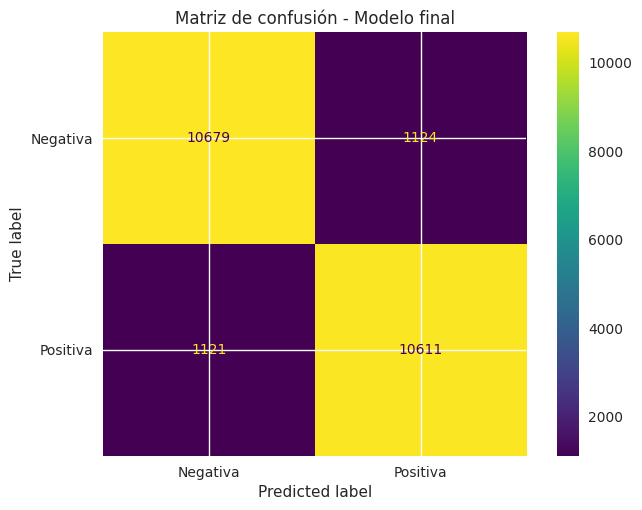

In [ ]:
cm = confusion_matrix(
    y_test_final,
    predicciones_test
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        'Negativa',
        'Positiva'
    ]
)

disp.plot()
plt.title('Matriz de confusión - Modelo final')
plt.show()

#### Interpretación de la matriz de clasificación

El reporte de clasificación mostró resultados equilibrados para ambas clases:

```
              precision    recall    f1-score

Negativa         0.91       0.90       0.90
Positiva         0.90       0.90       0.90
```

Esto es importante porque el modelo no presenta una diferencia importante entre su capacidad para identificar reseñas positivas y negativas.

El rendimiento equilibrado entre las dos clases también es consistente con la distribución original del conjunto de datos, donde ambas categorías tenían prácticamente la misma cantidad de observaciones.

## Mis reseñas

In [ ]:
# puedes eliminar por completo estas reseñas y probar tus modelos en tus propias reseñas; las que se muestran a continuación son solo ejemplos

reviews_prueba =[
    'I did not simply like it, not my kind of movie.',
    'Well, I was bored and felt asleep in the middle of the movie.',
    'I was really fascinated with the movie',
    'Even the actors looked really old and disinterested, and they got paid to be in the movie. What a soulless cash grab.',
    'I didn\'t expect the reboot to be so good! Writers really cared about the source material',
    'The movie had its upsides and downsides, but I feel like overall it\'s a decent flick. I could see myself going to see it again.',
    'What a rotten attempt at a comedy. Not a single joke lands, everyone acts annoying and loud, even kids won\'t like this!',
    'Launching on Netflix was a brave move & I really appreciate being able to binge on episode after episode, of this exciting intelligent new drama.',
    "This movie was absolutely fantastic. The acting was excellent and the story was engaging from beginning to end.",
    "One of the worst movies I have ever seen. The plot was boring and the acting was terrible.",    
    "The movie had some interesting ideas, but the story was too slow and the ending was disappointing.",    
    "I loved this film. The characters were memorable, the music was beautiful and I would definitely watch it again.",    
    "What a complete waste of time. Nothing interesting happens and the characters are extremely annoying.",    
    "The movie was not bad, but I expected much more from the director."
]

In [ ]:
# Limpiamos las reseñas

reviews_prueba_limpias = pd.Series(
    reviews_prueba
).apply(
    fp.limpiar_y_expandir_texto
)


In [ ]:
# Prueba con los mejores modelos de cada tipo
## Tratamiento de las predicciones LR 
pred_lr = fp.clasificar_reviews(
    reviews_prueba_limpias,
    tfidf_base,
    mejor_modelo_lr,
    'Logistic Regression'
)
## Tratamiento de nltk
reviews_prueba_nltk = reviews_prueba_limpias.apply(
    fp.lematizar_texto_nltk
)
## predicciones nltk
pred_lr_nltk = fp.clasificar_reviews(
    reviews_prueba_nltk,
    tfidf_nltk,
    mejor_modelo_lr_nltk,
    'Logistic Regression + NLTK'
)

# Tratamiento para spaCy
reviews_prueba_spacy = reviews_prueba_limpias.apply(
    lematizar_texto_spacy
)
# Predicciones para SpaCy
pred_lr_spacy = fp.clasificar_reviews(
    reviews_prueba_spacy,
    tfidf_spacy,
    mejor_modelo_lr_spacy,
    'Logistic Regression + spaCy'
)

# Predicciones LinearSVC unigramas
pred_svc = fp.clasificar_reviews(
    reviews_prueba_limpias,
    tfidf_base,
    mejor_modelo_svc,
    'LinearSVC'
)

# Predicciones Lr bigrama
pred_lr_bigram = fp.clasificar_reviews(
    reviews_prueba_limpias,
    tfidf_bigram,
    mejor_modelo_lr_bigram,
    'Logistic Regression + Bigramas'
)

# Prediccion SVC bigrama
pred_svc_bigram = fp.clasificar_reviews(
    reviews_prueba_limpias,
    tfidf_bigram,
    mejor_modelo_svc_bigram,
    'LinearSVC + Bigramas'
)
# Predicciones LightGBM
pred_lgbm = fp.clasificar_reviews(
    reviews_prueba_limpias,
    tfidf_bigram,
    mejor_modelo_lgbm,
    'LightGBM + Bigramas'
)

In [ ]:
# Unir resultados
resultados_reviews = pd.DataFrame({
    
    'Review': reviews_prueba,
    
    'Logistic Regression':
        pred_lr['Logistic Regression'],
    
    'Logistic Regression + NLTK':
        pred_lr_nltk[
            'Logistic Regression + NLTK'
        ],
    
    'Logistic Regression + spaCy':
        pred_lr_spacy[
            'Logistic Regression + spaCy'
        ],

    
    'LinearSVC':
        pred_svc['LinearSVC'],
    
    'Logistic Regression + Bigramas':
        pred_lr_bigram[
            'Logistic Regression + Bigramas'
        ],
    
    'LinearSVC + Bigramas':
        pred_svc_bigram[
            'LinearSVC + Bigramas'
        ],
    
    'LightGBM + Bigramas':
        pred_lgbm[
            'LightGBM + Bigramas'
        ]
})

# Convierte etiquetas a texto para facilitar lectura
columnas_modelos = resultados_reviews.columns[1:]

for columna in columnas_modelos:
    
    resultados_reviews[columna] = (
        resultados_reviews[columna]
        .map({
            0: 'Negativa',
            1: 'Positiva'
        })
    )

display(resultados_reviews)

,Review,Logistic Regression,Logistic Regression + NLTK,Logistic Regression + spaCy,LinearSVC,Logistic Regression + Bigramas,LinearSVC + Bigramas,LightGBM + Bigramas
0,"I did not simply like it, not my kind of movie.",Negativa,Negativa,Negativa,Negativa,Negativa,Negativa,Positiva
1,"Well, I was bored and felt asleep in the middl...",Negativa,Negativa,Negativa,Negativa,Negativa,Negativa,Positiva
2,I was really fascinated with the movie,Positiva,Positiva,Positiva,Positiva,Positiva,Positiva,Positiva
3,Even the actors looked really old and disinter...,Negativa,Negativa,Negativa,Negativa,Negativa,Negativa,Negativa
4,I didn't expect the reboot to be so good! Writ...,Negativa,Negativa,Negativa,Negativa,Negativa,Negativa,Positiva
5,"The movie had its upsides and downsides, but I...",Positiva,Positiva,Positiva,Positiva,Positiva,Positiva,Positiva
6,What a rotten attempt at a comedy. Not a singl...,Negativa,Negativa,Negativa,Negativa,Negativa,Negativa,Negativa
7,Launching on Netflix was a brave move & I real...,Positiva,Positiva,Positiva,Positiva,Positiva,Positiva,Positiva
8,This movie was absolutely fantastic. The actin...,Positiva,Positiva,Positiva,Positiva,Positiva,Positiva,Positiva
9,One of the worst movies I have ever seen. The ...,Negativa,Negativa,Negativa,Negativa,Negativa,Negativa,Negativa


### Conclusion sobre clasificación de reseñas escritas manualmente

Los modelos mostraron una alta coincidencia en la mayoría de las reseñas.

Por ejemplo, las opiniones claramente positivas fueron correctamente identificadas:

*"This movie was absolutely fantastic. The acting was excellent and the story was engaging from beginning to end."*

Todos los modelos la clasificaron como positiva.

También ocurrió lo mismo con opiniones claramente negativas:

*"One of the worst movies I have ever seen. The plot was boring and the acting was terrible."*

Todos los modelos la clasificaron como negativa.

Las diferencias aparecieron principalmente en algunas reseñas más complejas.

Por ejemplo:

*"I did not simply like it, not my kind of movie."*

Los modelos lineales la clasificaron como negativa, mientras que LightGBM la clasificó como positiva.

Algo similar ocurrió con:

*"Well, I was bored and felt asleep in the middle..."*

Los modelos basados en Logistic Regression y LinearSVC la identificaron como negativa, pero LightGBM la clasificó como positiva.

También apareció una diferencia interesante en:

**"I didn't expect the reboot to be so good!"**

Los modelos lineales la clasificaron como negativa, mientras que LightGBM la clasificó como positiva.

Este caso muestra una limitación de la representación basada en frecuencia de términos: aunque la expresión contiene una valoración positiva clara *"so good"*, también incluye una negación, *"didn't expect"*, que puede afectar la interpretación del modelo.

Por otra parte, la clasificación:

*"The movie was not bad, but I expected much more from the director."*

fue identificada como negativa por todos los modelos. Esto es razonable, ya que, aunque contiene la expresión "not bad", la segunda parte introduce una valoración negativa o de decepción.

## Conclusión general

El objetivo del proyecto fue construir un sistema capaz de clasificar automáticamente reseñas de películas como positivas o negativas y alcanzar un valor mínimo de F1 = 0.85.

Se probaron diferentes estrategias de procesamiento de texto, distintos modelos lineales y un modelo basado en potenciación del gradiente.

El flujo experimental permitió llegar a las siguientes conclusiones principales:

1. El conjunto de datos está prácticamente equilibrado, por lo que no fue necesario aplicar técnicas de balanceo.
2. La limpieza básica del texto fue más efectiva que la lematización con NLTK o spaCy para este conjunto de datos y estos modelos.
3. Logistic Regression y LinearSVC obtuvieron resultados muy similares utilizando unigramas, aunque LinearSVC fue considerablemente más rápido.
4. La incorporación de bigramas fue la mejora más importante del proyecto, permitiendo capturar parcialmente relaciones entre palabras y expresiones frecuentes.
5. LinearSVC + TF-IDF con unigramas y bigramas fue el mejor modelo durante la validación, alcanzando un F1 de 0.913855.
6. Después de reentrenar el modelo con todo el conjunto de entrenamiento, obtuvo un F1 de 0.904334 sobre el conjunto de prueba, confirmando una buena capacidad de generalización.
7. LightGBM no resultó competitivo para esta representación de los datos, obteniendo un F1 inferior y requiriendo un tiempo de entrenamiento mucho mayor.

En conclusión, el modelo final seleccionado fue LinearSVC con C=0.5 y una representación TF-IDF basada en unigramas y bigramas. El modelo superó ampliamente el requisito establecido de F1 ≥ 0.85 y demostró ser una solución eficiente y adecuada para la clasificación automática del sentimiento en reseñas de películas.

Resultado final

```
Modelo:
LinearSVC + TF-IDF (unigramas y bigramas)

Validación:
F1 = 0.913855

Prueba final:
F1 = 0.904334

Requisito:
F1 ≥ 0.85

Estado:
✓ OBJETIVO CUMPLIDO
```